In [ ]:
import numpy as np
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split

# roll no: M26MAC003 -> seed 26003
seed = 26003
torch.manual_seed(seed)
np.random.seed(seed)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Using device:", device)

# cifar10 normalization
tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.247, 0.243, 0.261))
])

train_raw = datasets.CIFAR10('./data', train=True, download=True, transform=tf)
test_set = datasets.CIFAR10('./data', train=False, download=True, transform=tf)

# 45k train, 5k val stratified split
labels = np.array(train_raw.targets)
idx = np.arange(len(labels))
tr_idx, val_idx = train_test_split(idx, test_size=5000, stratify=labels, random_state=seed)

# save split
np.save('train_idx.npy', tr_idx)
np.save('val_idx.npy', val_idx)

train_set = torch.utils.data.Subset(train_raw, tr_idx)
val_set = torch.utils.data.Subset(train_raw, val_idx)

train_loader = torch.utils.data.DataLoader(train_set, batch_size=128, shuffle=True)
val_loader = torch.utils.data.DataLoader(val_set, batch_size=128, shuffle=False)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=128, shuffle=False)

print("Done! Train:", len(train_set), "Val:", len(val_set), "Test:", len(test_set))

Using device: cuda


100%|██████████| 170M/170M [15:26<00:00, 184kB/s]


Done! Train: 45000 Val: 5000 Test: 10000


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Shallow & Wide MLP
class ShallowMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3072, 384),
            nn.ReLU(),
            nn.Linear(384, 10)
        )
    def forward(self, x):
        return self.net(x)

#  Deep & Narrow MLP
class DeepMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3072, 320),
            nn.ReLU(),
            nn.Linear(320, 256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )
    def forward(self, x):
        return self.net(x)

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

shallow_net = ShallowMLP().to(device)
deep_net = DeepMLP().to(device)

print(f"Shallow MLP Parameters: {count_params(shallow_net):,}")
print(f"Deep MLP Parameters:    {count_params(deep_net):,}")

# Training helper
def train_model(model, train_loader, val_loader, epochs=15, lr=0.001):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

    for epoch in range(epochs):
        # train
        model.train()
        total_loss, correct, total = 0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            total += len(y)

        tr_loss = total_loss / total
        tr_acc = correct / total

        # val
        model.eval()
        v_loss, v_correct, v_total = 0, 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                out = model(x)
                loss = criterion(out, y)
                v_loss += loss.item() * len(y)
                v_correct += (out.argmax(1) == y).sum().item()
                v_total += len(y)

        val_loss = v_loss / v_total
        val_acc = v_correct / v_total

        history['train_loss'].append(tr_loss)
        history['train_acc'].append(tr_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        print(f"Epoch [{epoch+1:02d}/{epochs}] | Train Acc: {tr_acc*100:.2f}% | Val Acc: {val_acc*100:.2f}%")

    return history

print("\n--- Training Shallow MLP ---")
hist_shallow = train_model(shallow_net, train_loader, val_loader, epochs=15)

print("\n--- Training Deep MLP ---")
hist_deep = train_model(deep_net, train_loader, val_loader, epochs=15)

Shallow MLP Parameters: 1,183,882
Deep MLP Parameters:    1,165,514

--- Training Shallow MLP ---
Epoch [01/15] | Train Acc: 41.16% | Val Acc: 45.88%
Epoch [02/15] | Train Acc: 49.11% | Val Acc: 46.76%
Epoch [03/15] | Train Acc: 52.10% | Val Acc: 48.38%
Epoch [04/15] | Train Acc: 54.69% | Val Acc: 48.84%
Epoch [05/15] | Train Acc: 56.96% | Val Acc: 48.34%
Epoch [06/15] | Train Acc: 59.05% | Val Acc: 50.72%
Epoch [07/15] | Train Acc: 60.78% | Val Acc: 50.20%
Epoch [08/15] | Train Acc: 62.41% | Val Acc: 49.42%
Epoch [09/15] | Train Acc: 64.14% | Val Acc: 50.78%
Epoch [10/15] | Train Acc: 65.70% | Val Acc: 51.86%
Epoch [11/15] | Train Acc: 67.40% | Val Acc: 51.32%
Epoch [12/15] | Train Acc: 69.26% | Val Acc: 52.26%
Epoch [13/15] | Train Acc: 70.85% | Val Acc: 50.84%
Epoch [14/15] | Train Acc: 71.65% | Val Acc: 51.86%
Epoch [15/15] | Train Acc: 73.67% | Val Acc: 49.90%

--- Training Deep MLP ---
Epoch [01/15] | Train Acc: 39.70% | Val Acc: 44.18%
Epoch [02/15] | Train Acc: 48.39% | Val Acc

Final Test Accuracy - Shallow MLP: 49.67%
Final Test Accuracy - Deep MLP:    52.38%


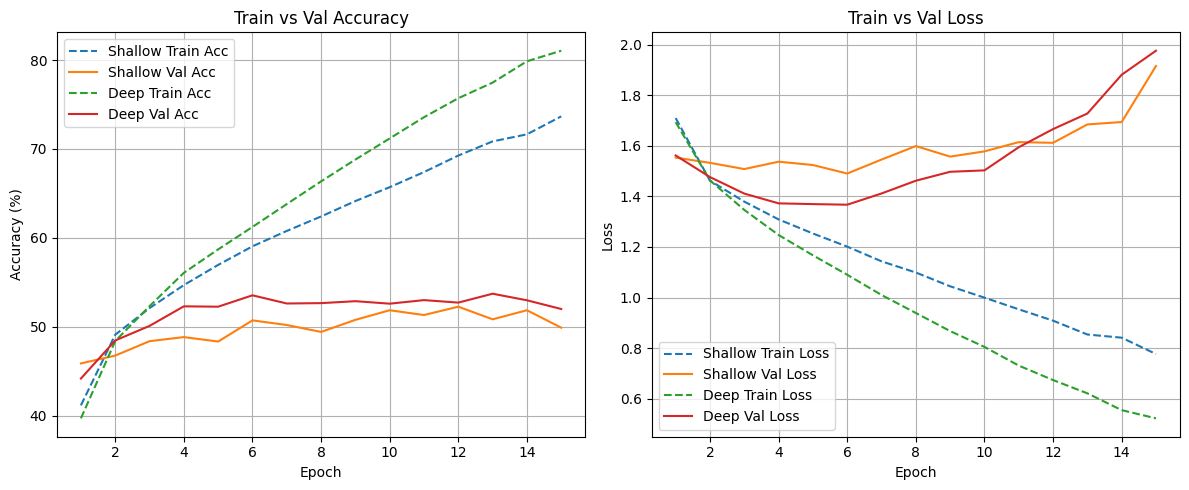

 Plot saved successfully!


In [ ]:
# evaluate on official test set
def evaluate_test(model):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            correct += (out.argmax(1) == y).sum().item()
            total += len(y)
    return (correct / total) * 100

test_acc_shallow = evaluate_test(shallow_net)
test_acc_deep = evaluate_test(deep_net)

print(f"Final Test Accuracy - Shallow MLP: {test_acc_shallow:.2f}%")
print(f"Final Test Accuracy - Deep MLP:    {test_acc_deep:.2f}%")

# plot training & validation curves
import os
os.makedirs('results/q1', exist_ok=True)

epochs_range = range(1, 16)
plt.figure(figsize=(12, 5))

# accuracy plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, [a*100 for a in hist_shallow['train_acc']], label='Shallow Train Acc', linestyle='--')
plt.plot(epochs_range, [a*100 for a in hist_shallow['val_acc']], label='Shallow Val Acc')
plt.plot(epochs_range, [a*100 for a in hist_deep['train_acc']], label='Deep Train Acc', linestyle='--')
plt.plot(epochs_range, [a*100 for a in hist_deep['val_acc']], label='Deep Val Acc')
plt.title('Train vs Val Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

# loss plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, hist_shallow['train_loss'], label='Shallow Train Loss', linestyle='--')
plt.plot(epochs_range, hist_shallow['val_loss'], label='Shallow Val Loss')
plt.plot(epochs_range, hist_deep['train_loss'], label='Deep Train Loss', linestyle='--')
plt.plot(epochs_range, hist_deep['val_loss'], label='Deep Val Loss')
plt.title('Train vs Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig('results/q1/q1a_curves.png', dpi=300)
plt.show()
print(" Plot saved successfully!")

In [ ]:
# Q1(b)
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# load saved indices
train_idx = np.load('train_idx.npy')
sub_idx = train_idx[:10000]

# get images and labels (already downloaded in ./data)
# agar train_data_full naam tha to wo use karlo
dataset = train_data_full if 'train_data_full' in locals() else train_raw

print("Extracting 10k images...")
imgs = torch.stack([dataset[i][0] for i in sub_idx])
labs = torch.tensor([dataset.targets[i] for i in sub_idx])

# 30% labels ko randomly corrupt karenge
clean_mask = torch.ones(10000, dtype=torch.bool)
clean_mask[:3000] = False
clean_mask = clean_mask[torch.randperm(10000)] # shuffle mask

noisy_labs = labs.clone()
noisy_labs[~clean_mask] = torch.randint(0, 10, (3000,))

print("Clean samples:", clean_mask.sum().item(), "| Noisy samples:", (~clean_mask).sum().item())

train_loader_noisy = DataLoader(
    TensorDataset(imgs, noisy_labs, clean_mask),
    batch_size=128,
    shuffle=True
)

# deep mlp model
mem_net = DeepMLP().to(device)
criterion = nn.CrossEntropyLoss()
opt = optim.Adam(mem_net.parameters(), lr=0.001)

clean_hist, noisy_hist, val_hist = [], [], []

for ep in range(25):
    mem_net.train()
    for x, y, _ in train_loader_noisy:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        loss = criterion(mem_net(x), y)
        loss.backward()
        opt.step()

    mem_net.eval()
    c_cor, c_tot = 0, 0
    n_cor, n_tot = 0, 0
    with torch.no_grad():
        for x, y, mask in train_loader_noisy:
            x, y, mask = x.to(device), y.to(device), mask.to(device)
            preds = mem_net(x).argmax(1)

            c_cor += (preds[mask] == y[mask]).sum().item()
            c_tot += mask.sum().item()

            n_cor += (preds[~mask] == y[~mask]).sum().item()
            n_tot += (~mask).sum().item()

        v_cor, v_tot = 0, 0
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            v_cor += (mem_net(x).argmax(1) == y).sum().item()
            v_tot += len(y)

    c_acc = 100 * c_cor / c_tot
    n_acc = 100 * n_cor / n_tot
    v_acc = 100 * v_cor / v_tot

    clean_hist.append(c_acc)
    noisy_hist.append(n_acc)
    val_hist.append(v_acc)

    print(f"Epoch {ep+1:2d} | Clean: {c_acc:5.1f}% | Noisy: {n_acc:5.1f}% | Val: {v_acc:5.1f}%")

Extracting 10k images...
Clean samples: 7000 | Noisy samples: 3000
Epoch  1 | Clean:  36.8% | Noisy:  11.1% | Val:  34.5%
Epoch  2 | Clean:  43.2% | Noisy:  12.9% | Val:  37.4%
Epoch  3 | Clean:  45.7% | Noisy:  15.4% | Val:  37.4%
Epoch  4 | Clean:  48.8% | Noisy:  15.4% | Val:  36.8%
Epoch  5 | Clean:  54.6% | Noisy:  19.5% | Val:  40.2%
Epoch  6 | Clean:  58.7% | Noisy:  21.2% | Val:  40.0%
Epoch  7 | Clean:  61.5% | Noisy:  25.7% | Val:  39.1%
Epoch  8 | Clean:  67.2% | Noisy:  29.7% | Val:  39.6%
Epoch  9 | Clean:  70.0% | Noisy:  34.5% | Val:  39.0%
Epoch 10 | Clean:  72.9% | Noisy:  39.5% | Val:  37.5%
Epoch 11 | Clean:  77.8% | Noisy:  48.6% | Val:  38.1%
Epoch 12 | Clean:  78.6% | Noisy:  53.0% | Val:  35.7%
Epoch 13 | Clean:  81.9% | Noisy:  56.8% | Val:  35.9%
Epoch 14 | Clean:  83.4% | Noisy:  62.5% | Val:  33.9%
Epoch 15 | Clean:  85.4% | Noisy:  66.3% | Val:  35.1%
Epoch 16 | Clean:  86.8% | Noisy:  70.0% | Val:  35.0%
Epoch 17 | Clean:  89.9% | Noisy:  78.6% | Val:  33.7

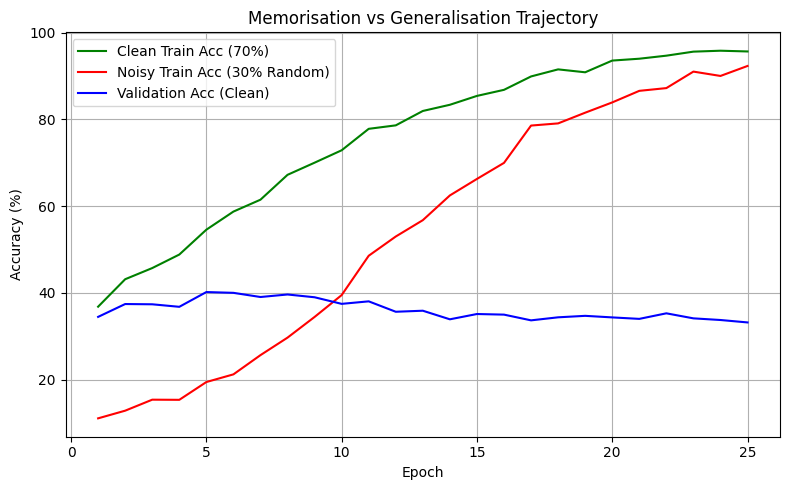

Memorisation plot saved to results/q1/q1b_memorization.png


In [ ]:
import matplotlib.pyplot as plt

# plot memorization trajectory
epochs_range = range(1, len(clean_hist) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, clean_hist, label='Clean Train Acc (70%)', color='green')
plt.plot(epochs_range, noisy_hist, label='Noisy Train Acc (30% Random)', color='red')
plt.plot(epochs_range, val_hist, label='Validation Acc (Clean)', color='blue')

plt.title('Memorisation vs Generalisation Trajectory')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig('results/q1/q1b_memorization.png', dpi=300)
plt.show()

print("Memorisation plot saved to results/q1/q1b_memorization.png")

In [ ]:
# Q2 (a)
import torch
import torch.nn as nn
import torch.optim as optim

# CNN matched to 1.16M parameters
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            # block 1: 32x32 -> 16x16
            nn.Conv2d(3, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # block 2: 16x16 -> 8x8
            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # block 3: 8x8 -> 4x4
            nn.Conv2d(128, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        # 128 * 4 * 4 = 2048
        self.classifier = nn.Sequential(
            nn.Linear(2048, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        feat = self.features(x)
        feat = feat.view(feat.size(0), -1)
        return self.classifier(feat)

clean_cnn = SimpleCNN().to(device)
print("CNN Parameters:", sum(p.numel() for p in clean_cnn.parameters() if p.requires_grad))
print("Deep MLP Parameters:", sum(p.numel() for p in deep_net.parameters() if p.requires_grad))

CNN Parameters: 935882
Deep MLP Parameters: 1165514


In [ ]:
import os


os.makedirs("checkpoints", exist_ok=True)

criterion = nn.CrossEntropyLoss()
opt = optim.Adam(clean_cnn.parameters(), lr=0.001)

print("Training CNN on clean CIFAR-10")

for ep in range(15):
    clean_cnn.train()
    tot_loss, cor, tot = 0, 0, 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        out = clean_cnn(x)
        loss = criterion(out, y)
        loss.backward()
        opt.step()

        tot_loss += loss.item() * len(y)
        cor += (out.argmax(1) == y).sum().item()
        tot += len(y)

    # val eval
    clean_cnn.eval()
    v_cor, v_tot = 0, 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            out = clean_cnn(x)
            v_cor += (out.argmax(1) == y).sum().item()
            v_tot += len(y)

    print(f"epoch {ep+1:2d} | train acc: {100*cor/tot:5.1f}% | val acc: {100*v_cor/v_tot:5.1f}%")

# test accuracy
clean_cnn.eval()
t_cor, t_tot = 0, 0
with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        t_cor += (clean_cnn(x).argmax(1) == y).sum().item()
        t_tot += len(y)

test_acc_cnn = 100 * t_cor / t_tot
print(f"\nFinal Test Accuracy - Clean CNN: {test_acc_cnn:.2f}%")

# save model cleanly
torch.save(clean_cnn.state_dict(), "checkpoints/clean_cnn.pt")
print("Saved clean_cnn.pt successfully!")

Training CNN on clean CIFAR-10
epoch  1 | train acc:  96.9% | val acc:  83.7%
epoch  2 | train acc:  97.5% | val acc:  81.1%
epoch  3 | train acc:  97.6% | val acc:  83.1%
epoch  4 | train acc:  97.6% | val acc:  83.8%
epoch  5 | train acc:  98.1% | val acc:  84.8%
epoch  6 | train acc:  98.1% | val acc:  83.6%
epoch  7 | train acc:  98.1% | val acc:  84.5%
epoch  8 | train acc:  98.2% | val acc:  83.9%
epoch  9 | train acc:  98.4% | val acc:  85.0%
epoch 10 | train acc:  98.3% | val acc:  84.8%
epoch 11 | train acc:  98.5% | val acc:  83.7%
epoch 12 | train acc:  98.6% | val acc:  84.3%
epoch 13 | train acc:  98.6% | val acc:  84.1%
epoch 14 | train acc:  98.7% | val acc:  85.2%
epoch 15 | train acc:  98.6% | val acc:  84.7%

Final Test Accuracy - Clean CNN: 84.45%
Saved clean_cnn.pt successfully!


In [ ]:
# Q.2(b):
# random permutation of 32x32 pixels
torch.manual_seed(SEED)
perm = torch.randperm(32 * 32)

def permute(x):
    b, c, h, w = x.shape
    x = x.view(b, c, -1)[:, :, perm]
    return x.view(b, c, h, w)

# retrain deep mlp on permuted data
perm_mlp = DeepMLP().to(device)
opt_mlp = optim.Adam(perm_mlp.parameters(), lr=0.001)

print("Training MLP on permuted data.")
for ep in range(15):
    perm_mlp.train()
    cor, tot = 0, 0
    for x, y in train_loader:
        x, y = permute(x).to(device), y.to(device)
        opt_mlp.zero_grad()
        out = perm_mlp(x)
        loss = criterion(out, y)
        loss.backward()
        opt_mlp.step()
        cor += (out.argmax(1) == y).sum().item()
        tot += len(y)
    print(f"epoch {ep+1:2d} | train acc: {100*cor/tot:5.1f}%")

# retrain cnn on permuted data
perm_cnn = SimpleCNN().to(device)
opt_cnn = optim.Adam(perm_cnn.parameters(), lr=0.001)

print("\nTraining CNN on permuted data.")
for ep in range(15):
    perm_cnn.train()
    cor, tot = 0, 0
    for x, y in train_loader:
        x, y = permute(x).to(device), y.to(device)
        opt_cnn.zero_grad()
        out = perm_cnn(x)
        loss = criterion(out, y)
        loss.backward()
        opt_cnn.step()
        cor += (out.argmax(1) == y).sum().item()
        tot += len(y)
    print(f"epoch {ep+1:2d} | train acc: {100*cor/tot:5.1f}%")

# evaluation on permuted test set
def test_model_perm(model):
    model.eval()
    cor, tot = 0, 0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = permute(x).to(device), y.to(device)
            cor += (model(x).argmax(1) == y).sum().item()
            tot += len(y)
    return 100 * cor / tot

test_acc_perm_mlp = test_model_perm(perm_mlp)
test_acc_perm_cnn = test_model_perm(perm_cnn)

print(f"\nFinal Test Accuracy on Permuted CIFAR-10:")
print(f"Permuted Deep MLP: {test_acc_perm_mlp:.2f}%")
print(f"Permuted Clean CNN: {test_acc_perm_cnn:.2f}%")

Training MLP on permuted data.
epoch  1 | train acc:  39.7%
epoch  2 | train acc:  48.4%
epoch  3 | train acc:  52.5%
epoch  4 | train acc:  55.9%
epoch  5 | train acc:  58.7%
epoch  6 | train acc:  61.5%
epoch  7 | train acc:  63.9%
epoch  8 | train acc:  66.2%
epoch  9 | train acc:  68.8%
epoch 10 | train acc:  71.0%
epoch 11 | train acc:  73.3%
epoch 12 | train acc:  75.7%
epoch 13 | train acc:  77.6%
epoch 14 | train acc:  79.3%
epoch 15 | train acc:  81.4%

Training CNN on permuted data.
epoch  1 | train acc:  28.2%
epoch  2 | train acc:  37.6%
epoch  3 | train acc:  43.9%
epoch  4 | train acc:  48.6%
epoch  5 | train acc:  53.0%
epoch  6 | train acc:  57.0%
epoch  7 | train acc:  61.2%
epoch  8 | train acc:  64.9%
epoch  9 | train acc:  69.5%
epoch 10 | train acc:  73.8%
epoch 11 | train acc:  77.2%
epoch 12 | train acc:  80.7%
epoch 13 | train acc:  83.6%
epoch 14 | train acc:  86.1%
epoch 15 | train acc:  87.9%

Final Test Accuracy on Permuted CIFAR-10:
Permuted Deep MLP: 51.55

Training occluded CNN...
epoch  1 | train acc:  49.7%
epoch  2 | train acc:  64.7%
epoch  3 | train acc:  70.1%
epoch  4 | train acc:  74.2%
epoch  5 | train acc:  77.1%
epoch  6 | train acc:  79.7%
epoch  7 | train acc:  81.6%
epoch  8 | train acc:  83.8%
epoch  9 | train acc:  85.7%
epoch 10 | train acc:  87.3%
epoch 11 | train acc:  88.8%
epoch 12 | train acc:  90.3%
epoch 13 | train acc:  92.1%
epoch 14 | train acc:  92.6%
epoch 15 | train acc:  94.0%

Occluded CNN Test Acc: 77.82%
Mean Confidence (Correct): 93.73%
Mean Confidence (Errors):  74.61%


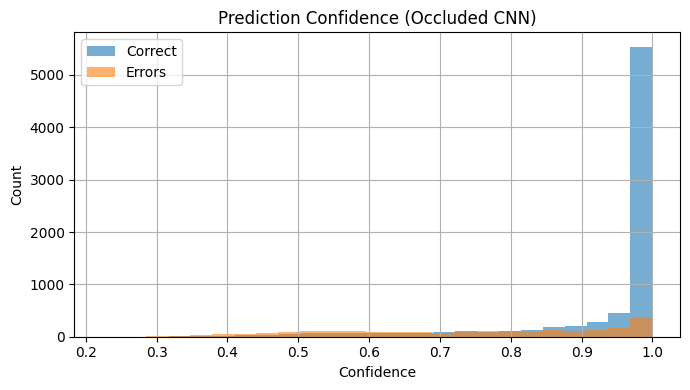

plot saved


In [ ]:
#Q2 (c)
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# 12x12 center occlusion
def occlude(x):
    x = x.clone()
    x[:, :, 10:22, 10:22] = 0
    return x

occ_cnn = SimpleCNN().to(device)
opt = optim.Adam(occ_cnn.parameters(), lr=0.001)

print("Training occluded CNN...")
for ep in range(15):
    occ_cnn.train()
    cor, tot = 0, 0
    for x, y in train_loader:
        x, y = occlude(x).to(device), y.to(device)
        opt.zero_grad()
        out = occ_cnn(x)
        loss = criterion(out, y)
        loss.backward()
        opt.step()
        cor += (out.argmax(1) == y).sum().item()
        tot += len(y)
    print(f"epoch {ep+1:2d} | train acc: {100*cor/tot:5.1f}%")

# eval and confidence analysis
occ_cnn.eval()
cor_conf = []
err_conf = []

with torch.no_grad():
    for x, y in test_loader:
        x, y = occlude(x).to(device), y.to(device)
        out = occ_cnn(x)
        probs = torch.softmax(out, dim=1)
        conf, preds = probs.max(1)

        mask = (preds == y)
        cor_conf.extend(conf[mask].cpu().numpy())
        err_conf.extend(conf[~mask].cpu().numpy())

cor_conf = np.array(cor_conf)
err_conf = np.array(err_conf)

test_acc_occ = 100 * len(cor_conf) / (len(cor_conf) + len(err_conf))

print(f"\nOccluded CNN Test Acc: {test_acc_occ:.2f}%")
print(f"Mean Confidence (Correct): {cor_conf.mean()*100:.2f}%")
print(f"Mean Confidence (Errors):  {err_conf.mean()*100:.2f}%")

# confidence histogram
plt.figure(figsize=(7, 4))
plt.hist(cor_conf, bins=25, alpha=0.6, label='Correct')
plt.hist(err_conf, bins=25, alpha=0.6, label='Errors')
plt.title('Prediction Confidence (Occluded CNN)')
plt.xlabel('Confidence')
plt.ylabel('Count')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('results/q2/q2c_confidence.png', dpi=300)
plt.show()
print("plot saved")

In [ ]:
import os
os.makedirs('results/q2', exist_ok=True)
plt.savefig('results/q2/q2c_confidence.png', dpi=300)
plt.show()
print("plot saved")

<Figure size 640x480 with 0 Axes>

plot saved


In [ ]:
import pandas as pd

#  q2 deliverable summary table
table_data = {
    "Model": [
        "Deep MLP",
        "Simple CNN",
        "Permuted MLP",
        "Permuted CNN",
        "Occluded CNN"
    ],
    "Parameters": [
        1165514,
        935882,
        1165514,
        935882,
        935882
    ],
    "Condition": [
        "Clean",
        "Clean",
        "Spatially Permuted",
        "Spatially Permuted",
        "12x12 Center Occluded"
    ],
    "Test Accuracy (%)": [
        52.38,
        84.45,
        51.55,
        51.47,
        77.82
    ]
}

df_q2 = pd.DataFrame(table_data)


print("QUESTION 2: FINAL EXPERIMENTAL COMPARISON")

print(df_q2.to_string(index=False))


# save as csv for report
import os
os.makedirs('results/q2', exist_ok=True)
df_q2.to_csv("results/q2/q2_summary_table.csv", index=False)
print("Saved summary table to results/q2/q2_summary_table.csv")

QUESTION 2: FINAL EXPERIMENTAL COMPARISON
       Model  Parameters             Condition  Test Accuracy (%)
    Deep MLP     1165514                 Clean              52.38
  Simple CNN      935882                 Clean              84.45
Permuted MLP     1165514    Spatially Permuted              51.55
Permuted CNN      935882    Spatially Permuted              51.47
Occluded CNN      935882 12x12 Center Occluded              77.82
Saved summary table to results/q2/q2_summary_table.csv



Training Autoencoder (Bottleneck: 64)...
Parameters: 450,627
epoch  1 | train mse: 0.3390
epoch  2 | train mse: 0.1761
epoch  3 | train mse: 0.1519
epoch  4 | train mse: 0.1394
epoch  5 | train mse: 0.1355
epoch  6 | train mse: 0.1332
epoch  7 | train mse: 0.1312
epoch  8 | train mse: 0.1300
epoch  9 | train mse: 0.1291
epoch 10 | train mse: 0.1281
--> Bottleneck 64 Val MSE: 0.1296

Training Autoencoder (Bottleneck: 256)...
Parameters: 1,237,251
epoch  1 | train mse: 0.3151
epoch  2 | train mse: 0.1418
epoch  3 | train mse: 0.1060
epoch  4 | train mse: 0.0882
epoch  5 | train mse: 0.0786
epoch  6 | train mse: 0.0714
epoch  7 | train mse: 0.0654
epoch  8 | train mse: 0.0620
epoch  9 | train mse: 0.0581
epoch 10 | train mse: 0.0554
--> Bottleneck 256 Val MSE: 0.0558

Training Autoencoder (Bottleneck: 1024)...
Parameters: 4,383,747
epoch  1 | train mse: 0.2978
epoch  2 | train mse: 0.1269
epoch  3 | train mse: 0.0922
epoch  4 | train mse: 0.0753
epoch  5 | train mse: 0.0651
epoch  6 | tr

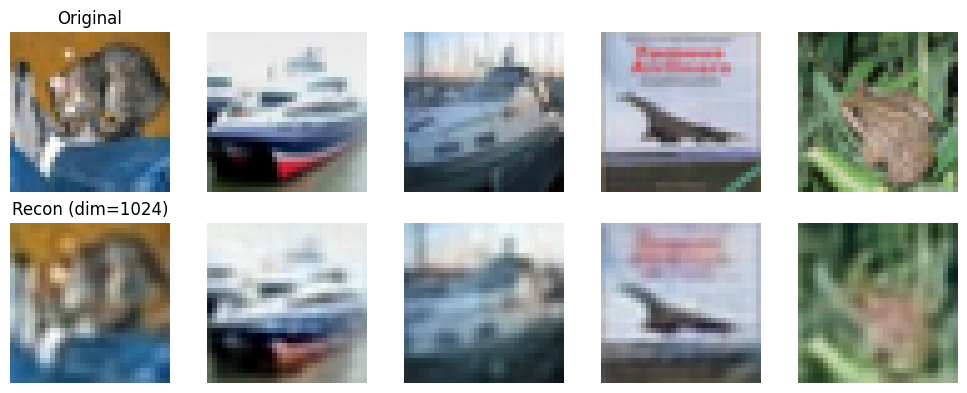

plot saved to results/q3/q3a_reconstructions.png


In [ ]:
# Q3 a)
import os
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

os.makedirs('results/q3', exist_ok=True)
os.makedirs('checkpoints', exist_ok=True)

# convolutional autoencoder
class ConvAutoencoder(nn.Module):
    def __init__(self, latent_dim=256):
        super().__init__()
        # encoder: 3x32x32 -> 128x4x4 -> latent_dim
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 128, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, latent_dim)
        )
        # decoder: latent_dim -> 128x4x4 -> 3x32x32
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128 * 4 * 4),
            nn.ReLU(),
            nn.Unflatten(1, (128, 4, 4)),
            nn.ConvTranspose2d(128, 64, 3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 3, 3, stride=2, padding=1, output_padding=1)
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

bottlenecks = [64, 256, 1024]
ae_models = {}
ae_val_errors = {}
criterion_mse = nn.MSELoss()

for b_size in bottlenecks:
    print(f"\nTraining Autoencoder (Bottleneck: {b_size})...")
    model = ConvAutoencoder(latent_dim=b_size).to(device)
    params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Parameters: {params:,}")

    opt = optim.Adam(model.parameters(), lr=0.001)

    for ep in range(10):
        model.train()
        tot_loss, tot = 0, 0
        for x, _ in train_loader:
            x = x.to(device)
            opt.zero_grad()
            recon = model(x)
            loss = criterion_mse(recon, x)
            loss.backward()
            opt.step()
            tot_loss += loss.item() * len(x)
            tot += len(x)
        print(f"epoch {ep+1:2d} | train mse: {tot_loss/tot:.4f}")

    # val reconstruction error
    model.eval()
    v_loss, v_tot = 0, 0
    with torch.no_grad():
        for x, _ in val_loader:
            x = x.to(device)
            recon = model(x)
            loss = criterion_mse(recon, x)
            v_loss += loss.item() * len(x)
            v_tot += len(x)

    val_mse = v_loss / v_tot
    ae_val_errors[b_size] = val_mse
    ae_models[b_size] = model
    print(f"--> Bottleneck {b_size} Val MSE: {val_mse:.4f}")

    torch.save(model.state_dict(), f"checkpoints/ae_{b_size}.pt")

# select best autoencoder based on val mse
best_b = min(ae_val_errors, key=ae_val_errors.get)
print(f"\nSelected Best Model: Bottleneck = {best_b} (Val MSE: {ae_val_errors[best_b]:.4f})")

# evaluate selected model on official test set
best_ae = ae_models[best_b]
best_ae.eval()
t_loss, t_tot = 0, 0
with torch.no_grad():
    for x, _ in test_loader:
        x = x.to(device)
        recon = best_ae(x)
        loss = criterion_mse(recon, x)
        t_loss += loss.item() * len(x)
        t_tot += len(x)

test_recon_mse = t_loss / t_tot
print(f"Final Test Reconstruction MSE (Bottleneck {best_b}): {test_recon_mse:.4f}")

# plot sample reconstructions
best_ae.eval()
sample_imgs, _ = next(iter(test_loader))
sample_imgs = sample_imgs[:5].to(device)
with torch.no_grad():
    recon_imgs = best_ae(sample_imgs)

# unnormalize for display
mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(1, 3, 1, 1).to(device)
std = torch.tensor([0.2470, 0.2435, 0.2616]).view(1, 3, 1, 1).to(device)
orig_disp = (sample_imgs * std + mean).clamp(0, 1).cpu()
recon_disp = (recon_imgs * std + mean).clamp(0, 1).cpu()

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i in range(5):
    axes[0, i].imshow(orig_disp[i].permute(1, 2, 0))
    axes[0, i].axis('off')
    if i == 0: axes[0, i].set_title("Original")

    axes[1, i].imshow(recon_disp[i].permute(1, 2, 0))
    axes[1, i].axis('off')
    if i == 0: axes[1, i].set_title(f"Recon (dim={best_b})")

plt.tight_layout()
plt.savefig('results/q3/q3a_reconstructions.png', dpi=300)
plt.show()
print("plot saved to results/q3/q3a_reconstructions.png")

In [ ]:
import os
import zipfile
from google.colab import files

zip_name = "assignment3_updated_progress.zip"
with zipfile.ZipFile(zip_name, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for folder in ['results', 'checkpoints']:
        for root, dirs, files_list in os.walk(folder):
            for f in files_list:
                zipf.write(os.path.join(root, f))
    if os.path.exists('train_idx.npy'):
        zipf.write('train_idx.npy')
    if os.path.exists('val_idx.npy'):
        zipf.write('val_idx.npy')

print("Saving and downloading updated zip...")
files.download(zip_name)


Saving and downloading updated zip...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!unzip -qo assignment3_updated_progress.zip

Original Clean CNN Test Acc: 84.45%
Noisy Images Test Acc:       50.47%
Clean AE Recon Test Acc:     45.78%
DAE Recon Test Acc:          37.18%


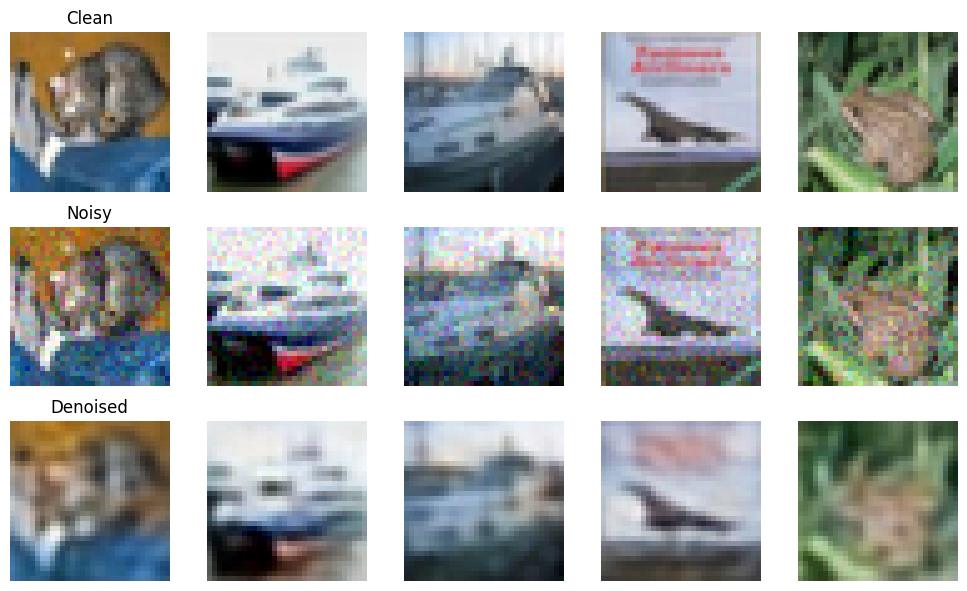

plot saved


In [ ]:
# Q3 b)
import os
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

os.makedirs('results/q3', exist_ok=True)

# cnn architecture from Q2
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        self.classifier = nn.Sequential(
            nn.Linear(2048, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 10)
        )
    def forward(self, x):
        feat = self.features(x)
        return self.classifier(feat.view(feat.size(0), -1))

# autoencoder
class ConvAutoencoder(nn.Module):
    def __init__(self, latent_dim=256):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 128, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128 * 4 * 4),
            nn.ReLU(),
            nn.Unflatten(1, (128, 4, 4)),
            nn.ConvTranspose2d(128, 64, 3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 3, 3, stride=2, padding=1, output_padding=1)
        )
    def forward(self, x):
        return self.decoder(self.encoder(x))

# load models
cnn = SimpleCNN().to(device)
cnn.load_state_dict(torch.load("checkpoints/clean_cnn.pt"))
cnn.eval()

clean_ae = ConvAutoencoder(latent_dim=1024).to(device)
clean_ae.load_state_dict(torch.load("checkpoints/ae_1024.pt"))
clean_ae.eval()

dae = ConvAutoencoder(latent_dim=256).to(device)
dae.load_state_dict(torch.load("checkpoints/dae.pt"))
dae.eval()

def add_noise(x):
    return x + 0.25 * torch.randn_like(x)

# test evaluation
c_noisy, c_clean, c_dae, tot = 0, 0, 0, 0

with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        noisy = add_noise(x)

        c_noisy += (cnn(noisy).argmax(1) == y).sum().item()
        c_clean += (cnn(clean_ae(noisy)).argmax(1) == y).sum().item()
        c_dae += (cnn(dae(noisy)).argmax(1) == y).sum().item()
        tot += len(y)

print(f"Original Clean CNN Test Acc: 84.45%")
print(f"Noisy Images Test Acc:       {100*c_noisy/tot:.2f}%")
print(f"Clean AE Recon Test Acc:     {100*c_clean/tot:.2f}%")
print(f"DAE Recon Test Acc:          {100*c_dae/tot:.2f}%")

# plot
sample, _ = next(iter(test_loader))
sample = sample[:5].to(device)
noisy_sample = add_noise(sample)
with torch.no_grad():
    denoised = dae(noisy_sample)

mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(1, 3, 1, 1).to(device)
std = torch.tensor([0.2470, 0.2435, 0.2616]).view(1, 3, 1, 1).to(device)

sample_disp = ((sample * std + mean).clamp(0, 1)).cpu()
noisy_disp = ((noisy_sample * std + mean).clamp(0, 1)).cpu()
dae_disp = ((denoised * std + mean).clamp(0, 1)).cpu()

fig, axes = plt.subplots(3, 5, figsize=(10, 6))
for i in range(5):
    axes[0, i].imshow(sample_disp[i].permute(1, 2, 0))
    axes[0, i].axis('off')
    if i == 0: axes[0, i].set_title("Clean")

    axes[1, i].imshow(noisy_disp[i].permute(1, 2, 0))
    axes[1, i].axis('off')
    if i == 0: axes[1, i].set_title("Noisy")

    axes[2, i].imshow(dae_disp[i].permute(1, 2, 0))
    axes[2, i].axis('off')
    if i == 0: axes[2, i].set_title("Denoised")

plt.tight_layout()
plt.savefig('results/q3/q3b_denoising.png', dpi=300)
plt.show()
print("plot saved")

Evaluating Latent Space (Bottleneck: 64)...
Bottleneck   64 | Recon MSE: 0.1296 | Linear Acc: 36.23%
Evaluating Latent Space (Bottleneck: 256)...
Bottleneck  256 | Recon MSE: 0.0558 | Linear Acc: 41.22%
Evaluating Latent Space (Bottleneck: 1024)...
Bottleneck 1024 | Recon MSE: 0.0425 | Linear Acc: 44.79%

--- Summary: Recon Quality vs Class Info ---
Bottleneck   64 -> MSE: 0.1296 | Linear Acc: 36.23%
Bottleneck  256 -> MSE: 0.0558 | Linear Acc: 41.22%
Bottleneck 1024 -> MSE: 0.0425 | Linear Acc: 44.79%


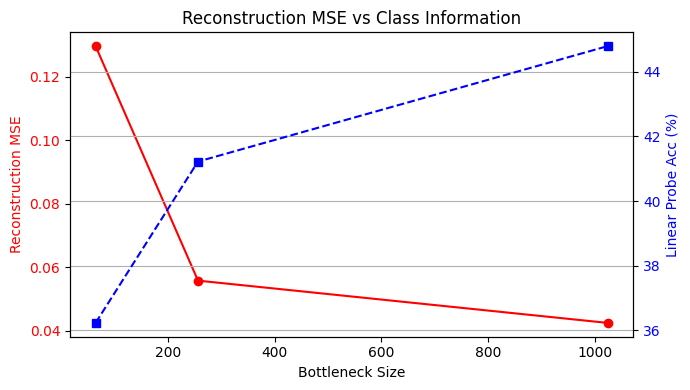

plot saved


In [ ]:
# Q3c)
import os
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# errors from q3a runs
ae_val_errors = {64: 0.1296, 256: 0.0558, 1024: 0.0425}

# feature extraction helper
def extract_features(encoder, loader):
    features, labels = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            z = encoder(x)
            features.append(z.cpu())
            labels.append(y)
    return torch.cat(features), torch.cat(labels)

linear_probe_results = {}

for b_size in [64, 256, 1024]:
    print(f"Evaluating Latent Space (Bottleneck: {b_size})...")

    ae = ConvAutoencoder(latent_dim=b_size).to(device)
    ae.load_state_dict(torch.load(f"checkpoints/ae_{b_size}.pt"))
    encoder = ae.encoder.eval()

    x_tr, y_tr = extract_features(encoder, train_loader)
    x_te, y_te = extract_features(encoder, test_loader)

    probe = nn.Linear(b_size, 10).to(device)
    probe_opt = optim.Adam(probe.parameters(), lr=0.005)
    criterion = nn.CrossEntropyLoss()

    probe_loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(x_tr, y_tr), batch_size=256, shuffle=True
    )

    # 10 epochs fast linear training
    for ep in range(10):
        probe.train()
        for bx, by in probe_loader:
            bx, by = bx.to(device), by.to(device)
            probe_opt.zero_grad()
            loss = criterion(probe(bx), by)
            loss.backward()
            probe_opt.step()

    probe.eval()
    with torch.no_grad():
        preds = probe(x_te.to(device)).argmax(1).cpu()
        acc = (preds == y_te).float().mean().item() * 100

    linear_probe_results[b_size] = acc
    print(f"Bottleneck {b_size:4d} | Recon MSE: {ae_val_errors[b_size]:.4f} | Linear Acc: {acc:.2f}%")

print("\n--- Summary: Recon Quality vs Class Info ---")
for b in [64, 256, 1024]:
    print(f"Bottleneck {b:4d} -> MSE: {ae_val_errors[b]:.4f} | Linear Acc: {linear_probe_results[b]:.2f}%")

# plot
b_list = [64, 256, 1024]
mse_list = [ae_val_errors[b] for b in b_list]
acc_list = [linear_probe_results[b] for b in b_list]

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.set_xlabel('Bottleneck Size')
ax1.set_ylabel('Reconstruction MSE', color='red')
ax1.plot(b_list, mse_list, color='red', marker='o')
ax1.tick_params(axis='y', labelcolor='red')

ax2 = ax1.twinx()
ax2.set_ylabel('Linear Probe Acc (%)', color='blue')
ax2.plot(b_list, acc_list, color='blue', marker='s', linestyle='--')
ax2.tick_params(axis='y', labelcolor='blue')

plt.title('Reconstruction MSE vs Class Information')
plt.grid(True)
plt.tight_layout()
plt.savefig('results/q3/q3c_recon_vs_class.png', dpi=300)
plt.show()
print("plot saved")

Extracting fixed representations for Q4...

--- Starting SVM Grid Sweep ---


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=2000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Kernel: linear | C:   0.01 | Train Acc:  57.2% | Val Acc:  40.7% | SV Frac: 0.916


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=2000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Kernel: linear | C:   0.10 | Train Acc:  52.4% | Val Acc:  36.5% | SV Frac: 0.959


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=2000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


... (9 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=2000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Kernel: rbf    | C:  10.00 | Train Acc:  98.7% | Val Acc:  47.2% | SV Frac: 0.959


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=2000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Kernel: rbf    | C: 100.00 | Train Acc: 100.0% | Val Acc:  45.0% | SV Frac: 0.955

Selected Best SVM: Kernel=rbf, C=10.0
Validation Accuracy: 47.20%
Final Test Accuracy: 46.40%


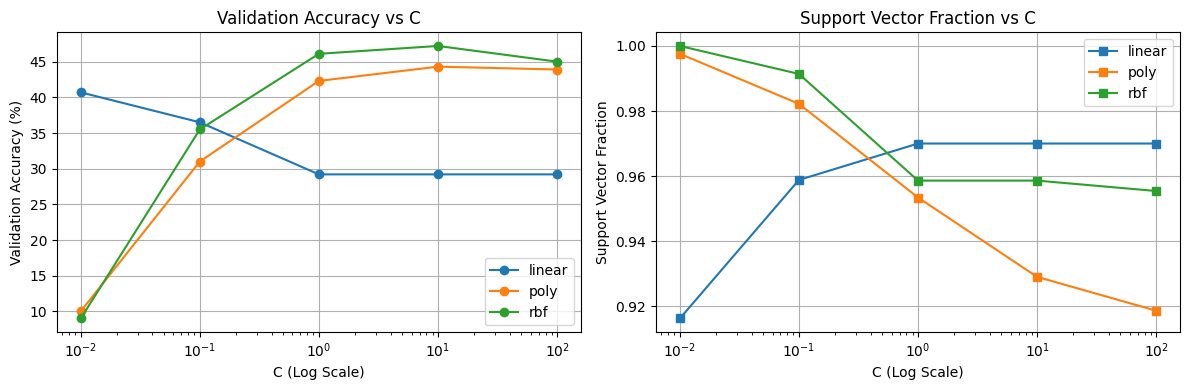

plot saved to results/q4/q4a_svm_sweep.png


In [ ]:
# Q4 a)
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

os.makedirs('results/q4', exist_ok=True)

# 1. choose fixed representation: best autoencoder (dim=256)
rep_ae = ConvAutoencoder(latent_dim=256).to(device)
rep_ae.load_state_dict(torch.load("checkpoints/ae_256.pt"))
rep_encoder = rep_ae.encoder.eval()

# extract features on stratified subset (5000 train, 1000 val, 2000 test)
print("Extracting fixed representations for Q4...")
x_train_all, y_train_all = extract_features(rep_encoder, train_loader)
x_val_all, y_val_all = extract_features(rep_encoder, val_loader)
x_test_all, y_test_all = extract_features(rep_encoder, test_loader)

# stratified subset for fast SVM
sub_tr = 5000
sub_val = 1000
sub_te = 2000

X_tr = x_train_all[:sub_tr].numpy()
Y_tr = y_train_all[:sub_tr].numpy()

X_val = x_val_all[:sub_val].numpy()
Y_val = y_val_all[:sub_val].numpy()

X_te = x_test_all[:sub_te].numpy()
Y_te = y_test_all[:sub_te].numpy()

# 2. grid sweep over C and Kernels
C_values = [0.01, 0.1, 1.0, 10.0, 100.0]
kernels = ['linear', 'poly', 'rbf']

results_table = []
val_accs = {k: [] for k in kernels}
sv_fracs = {k: [] for k in kernels}

best_val_acc = -1
best_model = None
best_params = None

print("\n--- Starting SVM Grid Sweep ---")
for k in kernels:
    for c in C_values:
        svm = SVC(C=c, kernel=k, max_iter=2000)
        svm.fit(X_tr, Y_tr)

        tr_acc = accuracy_score(Y_tr, svm.predict(X_tr)) * 100
        val_acc = accuracy_score(Y_val, svm.predict(X_val)) * 100
        sv_frac = len(svm.support_) / len(X_tr)

        val_accs[k].append(val_acc)
        sv_fracs[k].append(sv_frac)

        results_table.append({
            'Kernel': k, 'C': c, 'Train_Acc': tr_acc, 'Val_Acc': val_acc, 'SV_Frac': sv_frac
        })
        print(f"Kernel: {k:6s} | C: {c:6.2f} | Train Acc: {tr_acc:5.1f}% | Val Acc: {val_acc:5.1f}% | SV Frac: {sv_frac:.3f}")

        # select best based on validation only
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model = svm
            best_params = (k, c)

# 3. evaluate selected best SVM on test set
test_acc_best_svm = accuracy_score(Y_te, best_model.predict(X_te)) * 100

print("\n" + "="*50)
print(f"Selected Best SVM: Kernel={best_params[0]}, C={best_params[1]}")
print(f"Validation Accuracy: {best_val_acc:.2f}%")
print(f"Final Test Accuracy: {test_acc_best_svm:.2f}%")
print("="*50)

# 4. plot: val accuracy & sv fraction vs C
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

for k in kernels:
    ax1.plot(C_values, val_accs[k], marker='o', label=f"{k}")
    ax2.plot(C_values, sv_fracs[k], marker='s', label=f"{k}")

ax1.set_xscale('log')
ax1.set_xlabel('C (Log Scale)')
ax1.set_ylabel('Validation Accuracy (%)')
ax1.set_title('Validation Accuracy vs C')
ax1.legend()
ax1.grid(True)

ax2.set_xscale('log')
ax2.set_xlabel('C (Log Scale)')
ax2.set_ylabel('Support Vector Fraction')
ax2.set_title('Support Vector Fraction vs C')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.savefig('results/q4/q4a_svm_sweep.png', dpi=300)
plt.show()
print("plot saved to results/q4/q4a_svm_sweep.png")

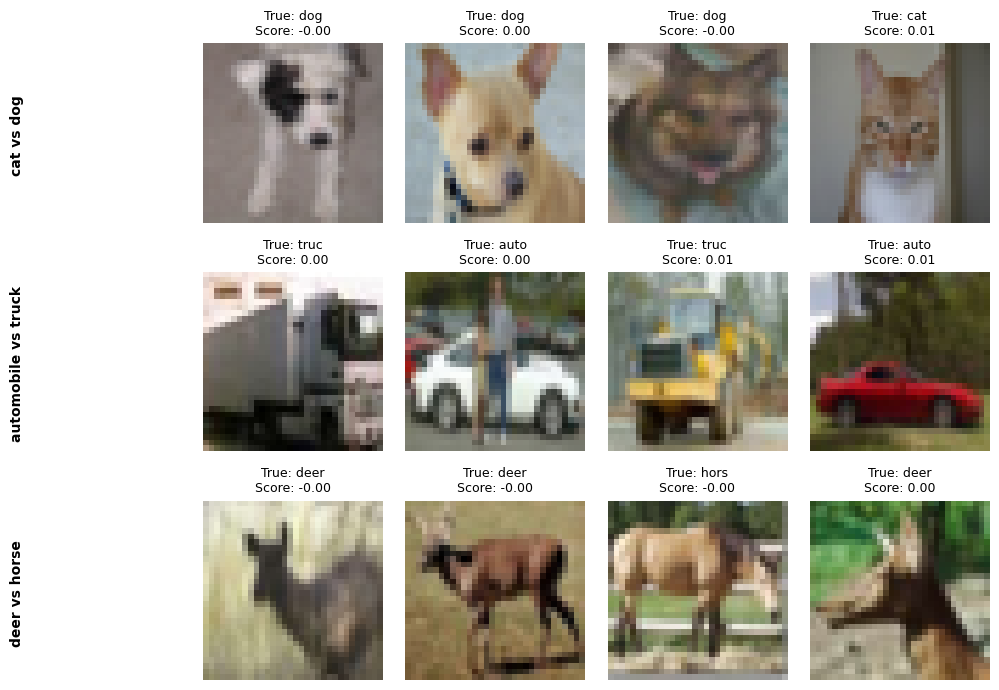

plot saved
Test ARI: 0.0399
Test NMI: 0.0881

Contingency Table:
            Cluster_0  Cluster_1  Cluster_2  Cluster_3  Cluster_4  Cluster_5  \
airplane           23         15          7         23         33         11   
automobile          6         23         48         29         11         16   
bird               30         42         27          6         14         13   
cat                22         42         26          7         16         14   
deer               25         43         32          9          3         14   
dog                35         51         15         13         13         12   
frog                6         49         46          7         14         31   
horse              26         28         21         19          6          5   
ship               17         11         18         44         10          5   
truck               8         11         35         60         13          5   

            Cluster_6  Cluster_7  Cluster_8  Cluster_9

In [ ]:
# Q4 b),c)
import os
import warnings
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, confusion_matrix

warnings.filterwarnings('ignore')

classes = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

# 3 difficult pairs: cat vs dog, automobile vs truck, deer vs horse
hard_pairs = [(3, 5), (1, 9), (4, 7)]

# decision function on test set
scores = best_model.decision_function(X_te)

mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
std = torch.tensor([0.2470, 0.2435, 0.2616]).view(3, 1, 1)

fig, axes = plt.subplots(3, 4, figsize=(10, 7))

for row, (c1, c2) in enumerate(hard_pairs):
    pair_label = f"{classes[c1]} vs {classes[c2]}"

    # filter test samples of these two classes
    mask = (Y_te == c1) | (Y_te == c2)
    pair_idx = np.where(mask)[0]

    # difference of decision scores (proximity to boundary)
    diff = scores[pair_idx][:, c1] - scores[pair_idx][:, c2]
    closest = pair_idx[np.argsort(np.abs(diff))[:4]]

    for col, idx in enumerate(closest):
        # unnormalize image for display
        img_tensor = test_set[idx][0]
        label = test_set[idx][1]
        img_disp = (img_tensor * std + mean).clamp(0, 1).permute(1, 2, 0)

        score_val = diff[np.where(pair_idx == idx)[0][0]]

        ax = axes[row, col]
        ax.imshow(img_disp)
        ax.set_title(f"True: {classes[label][:4]}\nScore: {score_val:.2f}", fontsize=9)
        ax.axis('off')

    axes[row, 0].text(-35, 16, pair_label, rotation=90, verticalalignment='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig('results/q4/q4b_hard_pairs.png', dpi=300)
plt.show()
print("plot saved")

# k-means clustering
kmeans = KMeans(n_clusters=10, random_state=seed, n_init=10)
kmeans.fit(X_tr)

clusters = kmeans.predict(X_te)

ari = adjusted_rand_score(Y_te, clusters)
nmi = normalized_mutual_info_score(Y_te, clusters)

print(f"Test ARI: {ari:.4f}")
print(f"Test NMI: {nmi:.4f}")

# contingency table
cont_mat = confusion_matrix(Y_te, clusters)
df_cont = pd.DataFrame(cont_mat, index=classes, columns=[f"Cluster_{i}" for i in range(10)])

print("\nContingency Table:")
print(df_cont)

df_cont.to_csv("results/q4/q4c_contingency_table.csv")
print("contingency table saved")